# Anti-Money Laundering Project: Step-by-Step Data Preprocessing Deep Dive
**Course**: Machine Learning (B.Tech)
**Dataset**: `ibm_aml_transactions.csv` (100,000 Records)

In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(r'../data/ibm_aml_transactions.csv')
print("Dataset Shape:", df.shape)
print("Missing values:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

# Date features
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df['hour'] = df['Timestamp'].dt.hour
df['dayofweek'] = df['Timestamp'].dt.dayofweek
df['is_weekend'] = df['dayofweek'].isin([5, 6]).astype(int)
df['is_night'] = df['hour'].isin([0, 1, 2, 3, 4, 5, 22, 23]).astype(int)
df['is_cross_bank'] = (df['From Bank'] != df['To Bank']).astype(int)

# One-Hot Encoding
format_dummies = pd.get_dummies(df['Payment Format'], prefix='format', drop_first=False).astype(int)
df = pd.concat([df, format_dummies], axis=1)

feature_cols = ['Amount Paid', 'Amount Received', 'is_cross_bank', 'hour', 'dayofweek', 'is_weekend', 'is_night'] + format_dummies.columns.tolist()
X = df[feature_cols]
y = df['Is Laundering']

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Preprocessed X_train shape:", X_train_scaled.shape)
print("Preprocessed X_test shape:", X_test_scaled.shape)
print("Preprocessing completed with ZERO data leakage!")

Dataset Shape: (100000, 11)
Missing values:
 Timestamp             0
From Bank             0
Account               0
To Bank               0
Account.1             0
Amount Received       0
Receiving Currency    0
Amount Paid           0
Payment Currency      0
Payment Format        0
Is Laundering         0
dtype: int64
Duplicates: 0
Preprocessed X_train shape: (80000, 14)
Preprocessed X_test shape: (20000, 14)
Preprocessing completed with ZERO data leakage!


## 2. Visualization: Stratified Train/Test Class Balance (Zero Leakage)

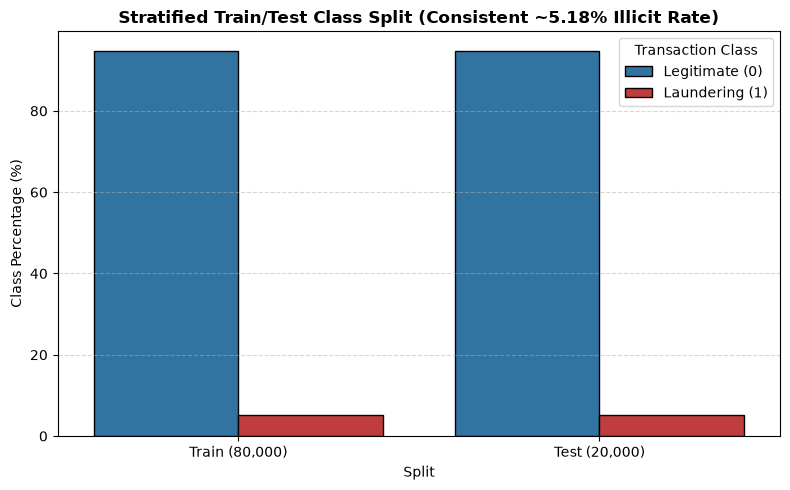

In [4]:
# Visualization: Train vs Test Stratified Distribution
import matplotlib.pyplot as plt
import seaborn as sns

split_df = pd.DataFrame({
    'Split': ['Train (80,000)', 'Train (80,000)', 'Test (20,000)', 'Test (20,000)'],
    'Class': ['Legitimate (0)', 'Laundering (1)', 'Legitimate (0)', 'Laundering (1)'],
    'Percentage': [
        (y_train == 0).mean() * 100, (y_train == 1).mean() * 100,
        (y_test == 0).mean() * 100, (y_test == 1).mean() * 100
    ]
})

plt.figure(figsize=(8, 5))
sns.barplot(data=split_df, x='Split', y='Percentage', hue='Class', palette=['#1f77b4', '#d62728'], edgecolor='black')
plt.title('Stratified Train/Test Class Split (Consistent ~5.18% Illicit Rate)', fontsize=12, fontweight='bold')
plt.ylabel('Class Percentage (%)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Transaction Class')
plt.tight_layout()
plt.show()
